# Section 3 · Notebook 2 — LangGraph + AgentCore Memory (short-term memory)

We give a LangGraph agent **session memory** by using Amazon Bedrock AgentCore Memory as its *checkpointer*. Every step of the conversation is saved automatically, so the agent can pick up where it left off — even from a different process or machine.

| | |
|:--|:--|
| Use case | Multi-step math calculations |
| Framework | LangGraph (via `langchain.agents.create_agent`) |
| Memory | AgentCore Memory — `AgentCoreMemorySaver` checkpointer |
| Complexity | Beginner |

```
 user ──► LangGraph agent ──► Bedrock model
               │  ▲
     save state│  │load state  (every step)
               ▼  │
        AgentCore Memory  (session_id = thread_id, actor_id)
```

**Prerequisites:** AWS credentials, Bedrock access, and IAM permissions for AgentCore Memory (`bedrock-agentcore:CreateMemory`, `CreateEvent`, `ListEvents`, `GetMemory`, `DeleteMemory`, ...).

In [1]:
%pip install -q -r requirements.txt


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: /private/tmp/scaler-code-venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


> If pip upgraded any packages, restart the kernel before continuing.

In [2]:
import os

from bedrock_agentcore.memory import MemoryClient
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langgraph_checkpoint_aws import AgentCoreMemorySaver

MODEL_ID = os.getenv("BEDROCK_MODEL_ID", "amazon.nova-lite-v1:0")
REGION = os.getenv("AWS_REGION", os.getenv("AWS_DEFAULT_REGION", "us-east-1"))
print(f"Model: {MODEL_ID} | Region: {REGION}")

Model: amazon.nova-lite-v1:0 | Region: us-east-1


### Create (or reuse) the AgentCore Memory resource

`create_or_get_memory` creates the memory the first time and waits until it is ACTIVE. Running the notebook again simply reuses it. No extraction strategies are needed for short-term memory.

In [3]:
client = MemoryClient(region_name=REGION)
memory = client.create_or_get_memory(
    name="MathLanggraphAgent",
    description="Short-term memory for the LangGraph math agent",
)
memory_id = memory["id"]
print("Memory ID:", memory_id, "| status:", memory.get("status"))

Memory ID: MathLanggraphAgent-m1bhKyHaUD | status: ACTIVE


### Configure the checkpointer and the model

- `memory_id` — the AgentCore Memory resource that stores checkpoints
- `region_name` — where it lives
- `MODEL_ID` — the Bedrock model that powers the agent

In [4]:
checkpointer = AgentCoreMemorySaver(memory_id, region_name=REGION)
llm = init_chat_model(MODEL_ID, model_provider="bedrock_converse", region_name=REGION)

### Math tools

In [5]:
@tool
def add(a: int, b: int) -> int:
    """Add two integers and return the result."""
    return a + b


@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the result."""
    return a * b


tools = [add, multiply]

### Build the agent with the AgentCore Memory checkpointer

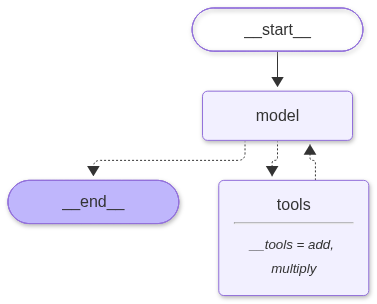

In [6]:
graph = create_agent(
    model=llm,
    tools=tools,
    system_prompt="You are a helpful assistant. Use the tools for every calculation.",
    checkpointer=checkpointer,
)
graph

### Run it

The checkpointer needs two IDs in the run config:
- `thread_id` → AgentCore **session_id** (one conversation)
- `actor_id` → AgentCore **actor_id** (the user or agent)

In [7]:
config = {
    "configurable": {
        "thread_id": "session-1",  # REQUIRED: maps to AgentCore session_id
        "actor_id": "react-agent-1",  # REQUIRED: maps to AgentCore actor_id
    }
}

inputs = {"messages": [{"role": "user", "content": "What is 1337 times 515321? Then add 412 and return the value to me."}]}

for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content=[{'type': 'reasoning_content', 'reasoning_content': {'text': 'The User has asked for two operations: first, to multiply 1337 by 515321, and second, to add 412 to the result of the multiplication. I need to use the "multiply" tool to perform the multiplication and then use the "add" tool to add 412 to the result. I will proceed with the multiplication first.'}}, {'type': 'tool_use', 'name': 'multiply', 'input': {'a': 1337, 'b': 515321}, 'id': 'tooluse_PxFGDtFuHGBbJ6RdFoTMyS'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '235ff87a-3cf7-4bc6-8462-9aaa400c074c', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 10 Nov 2026 07:06:46 GMT', 'content-type': 'application/json', 'content-length': '636', 'connection': 'keep-alive', 'x-amzn-requestid': '235ff87a-3cf7-4bc6-8462-9aaa400c074c'}, 'RetryAttempts': 0}, 'stopReason': 'tool_use', 'metrics': {'latencyMs': [853]}, 'model_provider': 'bedrock_converse', 'model_name':

### Inspect the saved state

In [8]:
for message in graph.get_state(config).values.get("messages"):
    print(f"{message.type}: {message.text}")
    print("=" * 40)

human: What is 1337 times 515321? Then add 412 and return the value to me.
ai: 
tool: 688984177
ai: 
tool: 688984589
ai: The result of 1337 times 515321 is 688984177. When you add 412 to this value, the final result is 688984589.


### Checkpoint history (most recent first)

In [9]:
for checkpoint in graph.get_state_history(config):
    print(
        f"Checkpoint {checkpoint.config['configurable']['checkpoint_id']} "
        f"— messages in state: {len(checkpoint.values.get('messages', []))}"
    )

Adding placeholder ToolMessage for orphaned tool_call 'add' (id: tooluse_hzZ1sFkRvEjjROjR1aPOfh) during checkpoint load
Adding placeholder ToolMessage for orphaned tool_call 'multiply' (id: tooluse_PxFGDtFuHGBbJ6RdFoTMyS) during checkpoint load


Checkpoint 1f1dcd54-bdd3-6aec-8005-aa3ba101ad83 — messages in state: 6
Checkpoint 1f1dcd54-b6b4-6072-8004-f3fe9bd7aa83 — messages in state: 5
Checkpoint 1f1dcd54-b6a7-60d4-8003-4095df4a3057 — messages in state: 5
Checkpoint 1f1dcd54-aec3-69d0-8002-8d0af6688f64 — messages in state: 3
Checkpoint 1f1dcd54-aeab-6790-8001-82eeeb052048 — messages in state: 3
Checkpoint 1f1dcd54-9f14-600c-8000-7083efefe199 — messages in state: 1
Checkpoint 1f1dcd54-9f06-6b0a-bfff-1ef90fea78e5 — messages in state: 0


### Memory persistence — continue the same session

In [10]:
inputs = {"messages": [{"role": "user", "content": "What were the first calculations I asked you to do?"}]}

for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content='The first calculations you asked me to do were:\n\n1. Multiply 1337 by 515321.\n2. Add 412 to the result of the first calculation.', additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '2ab4778a-a88d-463b-968d-bda9285d994a', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 10 Nov 2026 07:07:24 GMT', 'content-type': 'application/json', 'content-length': '334', 'connection': 'keep-alive', 'x-amzn-requestid': '2ab4778a-a88d-463b-968d-bda9285d994a'}, 'RetryAttempts': 0}, 'stopReason': 'end_turn', 'metrics': {'latencyMs': [502]}, 'model_provider': 'bedrock_converse', 'model_name': 'amazon.nova-lite-v1:0'}, id='lc_run--01a1c448-6eb7-762a-b9c8-86fe831e1e01-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 687, 'output_tokens': 44, 'total_tokens': 731, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}})]}}


### Session isolation — a new session starts empty

In [11]:
config = {
    "configurable": {
        "thread_id": "session-2",  # new session
        "actor_id": "react-agent-1",  # same actor
    }
}

inputs = {"messages": [{"role": "user", "content": "What values did I ask you to multiply and add?"}]}
for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content=[{'type': 'reasoning_content', 'reasoning_content': {'text': "The User is asking for the values that were previously used for multiplication and addition operations. However, I do not have any previous interactions or tool results that provide this information. Therefore, I cannot directly answer the User's question based on existing data."}}, {'type': 'text', 'text': '\n\nI do not have the information regarding the specific values you asked me to multiply and add previously. Can you provide more details or specify the values you want to use for these operations?'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '70ad2d36-7d9b-4779-9864-ed982bd737eb', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 10 Nov 2026 07:07:30 GMT', 'content-type': 'application/json', 'content-length': '703', 'connection': 'keep-alive', 'x-amzn-requestid': '70ad2d36-7d9b-4779-9864-ed982bd737eb'}, 'RetryAttempts': 0}, 'stopReason': 'end

## Summary

1. Created an AgentCore Memory resource
2. Used `AgentCoreMemorySaver` as the LangGraph checkpointer
3. Saw state persist across turns in the same session
4. Saw a new session start with a clean slate

### Clean up

In [12]:
client.delete_memory_and_wait(memory_id=memory_id, max_wait=300, poll_interval=10)
print("Deleted memory", memory_id)

Deleted memory MathLanggraphAgent-m1bhKyHaUD
